<a href="https://colab.research.google.com/github/DiegoMartell/Machine-Learning/blob/main/hands-on/Hands_on_4_ClassificationPerceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Hands-on 4: Clasificación con Perceptrón
### Implementación paso a paso con Scikit-Learn

> **Objetivo del Tutorial**
> Este notebook es una guía interactiva para implementar el algoritmo del **Perceptrón**, el bloque de construcción más básico de las Redes Neuronales, utilizando Python y Scikit-Learn.
> Seguiremos fielmente la metodología del **Pipeline de Machine Learning** paso a paso.

## 1. Fundamentos Teóricos del Perceptrón

El **Perceptrón** fue inventado en 1957 por Frank Rosenblatt y es la forma más simple de una Red Neuronal Artificial.

* **¿Qué es?** Es un algoritmo de aprendizaje supervisado utilizado para **clasificación binaria** (separar datos en dos grupos).
* **¿Cómo funciona?** Recibe múltiples señales de entrada, asigna una importancia (peso) a cada una, las suma y pasa el resultado por una función de activación. Si la suma supera cierto umbral, la neurona "se activa" (predice la clase 1), de lo contrario, se queda inactiva (predice la clase 0).
* **Limitación principal:** Es un **clasificador lineal**. Esto significa que solo puede resolver problemas donde las clases se puedan separar perfectamente con una línea recta.

## 2. Modelo Matemático y Analítico

El modelo matemático detrás de la neurona se divide en dos pasos:

### A. Combinación Lineal (La suma ponderada)
Multiplicamos cada característica de entrada ($x$) por su respectivo peso ($w$) y sumamos el sesgo ($b$):
$$z = (w_1 \cdot x_1) + (w_2 \cdot x_2) + \dots + (w_n \cdot x_n) + b$$

### B. Función de Activación (Función Escalón / Step Function)
Para decidir a qué clase pertenece, el resultado $z$ pasa por una función escalón unitario que actúa como un interruptor:
* Si $z \ge 0 \implies$ Predicción $= 1$
* Si $z < 0 \implies$ Predicción $= 0$

### C. Regla de Aprendizaje
Si el Perceptrón se equivoca, ajusta sus pesos calculando el error (Dato Real - Predicción) multiplicado por una tasa de aprendizaje ($\eta$):
$$w_{nuevo} = w_{viejo} + \eta \cdot (y_{real} - \hat{y}_{predicho}) \cdot x$$

In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Librerías base cargadas correctamente.")

Librerías base cargadas correctamente.


## 3. Pipeline de Machine Learning

### 3.1 Recolección y Descripción del Dataset
Para que el Perceptrón funcione perfectamente, necesita un problema **linealmente separable**. Utilizaremos un archivo `.csv` clásico (Dataset Iris), pero tomaremos **solo 2 especies** (Setosa y Versicolor) y **2 características** (Longitud del sépalo y Longitud del pétalo) para mantener el problema simple y visualizable en 2D.

In [8]:
# URL pública del archivo CSV ligero
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/iris.csv"
# Definimos manualmente los nombres de las columnas porque el CSV original no tiene encabezado
columnas = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
# Leemos el archivo CSV y lo guardamos en un DataFrame llamado 'df'
df = pd.read_csv(url, header=None, names=columnas)

# Filtramos el dataset para quedarnos solo con 2 especies (Setosa y Versicolor)
df_filtrado = df[df['species'].isin(['Iris-setosa', 'Iris-versicolor'])]

# Mostramos las primeras 5 filas del dataset filtrado para inspeccionar los datos
display(df_filtrado.head())

# Mostramos un resumen de cuántas muestras tenemos por especie
print("\nDistribución de las clases:")
print(df_filtrado['species'].value_counts())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa



Distribución de las clases:
species
Iris-setosa        50
Iris-versicolor    50
Name: count, dtype: int64


### 3.2 Análisis Exploratorio de los Datos (Scatter Plot)
Antes de entrenar a la neurona, comprobamos visualmente si las dos clases se pueden separar con una línea recta.

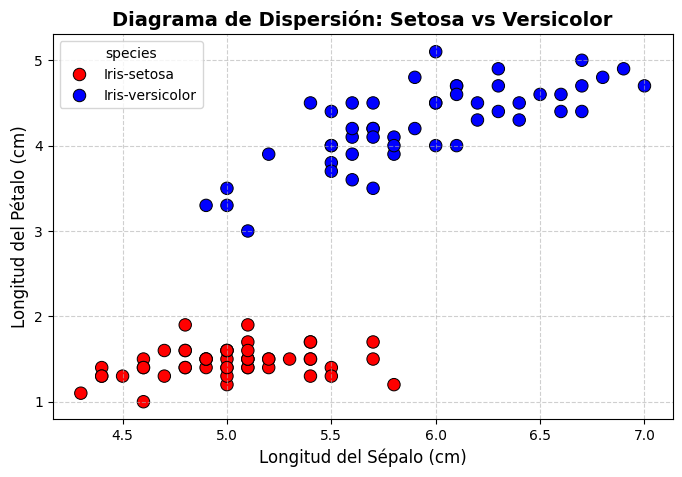

Como se observa, existe un espacio vacío claro entre las flores rojas y azules. ¡El Perceptrón podrá trazar una línea perfecta ahí!


In [9]:
# Creamos una nueva figura de tamaño 8x5 pulgadas
plt.figure(figsize=(8, 5))

# Creamos un gráfico de dispersión (Scatter Plot) usando seaborn
sns.scatterplot(
    data=df_filtrado,          # Usamos el dataframe filtrado
    x='sepal_length',          # Eje X: Longitud del sépalo
    y='petal_length',          # Eje Y: Longitud del pétalo
    hue='species',             # Coloreamos los puntos según la especie
    palette=['red', 'blue'],   # Definimos colores específicos (Rojo y Azul)
    s=80,                      # Tamaño de los puntos
    edgecolor='black'          # Color del borde de los puntos
)

# Agregamos un título principal al gráfico
plt.title('Diagrama de Dispersión: Setosa vs Versicolor', fontsize=14, fontweight='bold')
# Etiquetamos el Eje X
plt.xlabel('Longitud del Sépalo (cm)', fontsize=12)
# Etiquetamos el Eje Y
plt.ylabel('Longitud del Pétalo (cm)', fontsize=12)
# Agregamos una cuadrícula para facilitar la lectura visual
plt.grid(True, linestyle='--', alpha=0.6)
# Mostramos el gráfico en pantalla
plt.show()

print("Como se observa, existe un espacio vacío claro entre las flores rojas y azules. ¡El Perceptrón podrá trazar una línea perfecta ahí!")

### 3.3 Preprocesamiento de Datos
Esta fase prepara matemáticamente los datos para el algoritmo dividiéndola en pasos clave:
1. **Mapeo de Clases:** Convertir texto a números (1 y 0).
2. **Splitting (División):** Separar datos para Entrenamiento y Prueba.
3. **Scaling (Escalado):** Estandarizar rangos numéricos para que la red neuronal aprenda más rápido.

In [10]:
# Importamos funciones de Scikit-Learn para dividir y escalar los datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- 3.3.1 Selección de Variables y Mapeo ---
# Extraemos solo las dos características numéricas seleccionadas (X)
X = df_filtrado[['sepal_length', 'petal_length']].values
# Extraemos las etiquetas de texto originales
y_texto = df_filtrado['species'].values
# Mapeamos el texto a enteros: 1 si es 'Iris-setosa', de lo contrario 0
y = np.where(y_texto == 'Iris-setosa', 1, 0)

# --- 3.3.2 Splitting (División de Entrenamiento y Prueba) ---
# Dividimos los datos: 80% para entrenar y 20% para validar (test)
# stratify=y asegura que la proporción de clases se mantenga en ambos sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- 3.3.3 Scaling (Escalado Estándar) ---
# Instanciamos el escalador estándar (resta la media y divide por desviación estándar)
scaler = StandardScaler()
# Calculamos los parámetros (fit) y transformamos los datos de entrenamiento
X_train_scaled = scaler.fit_transform(X_train)
# Transformamos los datos de prueba (test) usando los parámetros del set de entrenamiento
X_test_scaled = scaler.transform(X_test)

print(f"Datos preparados. Muestras de entrenamiento: {X_train_scaled.shape[0]} | Muestras de prueba: {X_test_scaled.shape[0]}")

Datos preparados. Muestras de entrenamiento: 80 | Muestras de prueba: 20


### 3.4 Selección y Entrenamiento del Modelo (El Perceptrón)
Scikit-Learn tiene una implementación directa de la neurona de Rosenblatt bajo el módulo `linear_model`.

In [11]:
# Importamos el clasificador Perceptron desde la librería de Scikit-Learn
from sklearn.linear_model import Perceptron

# Instanciamos el modelo definiendo sus hiperparámetros:
# max_iter = Número máximo de pasadas por el dataset (épocas)
# eta0 = Tasa de aprendizaje (qué tan grandes son los pasos al ajustar los pesos)
# random_state = 42 asegura que si ejecutas esto mil veces, la aleatoriedad sea igual
perceptrón = Perceptron(max_iter=1000, eta0=0.1, random_state=42)

# Entrenamos el modelo con los datos escalados y las etiquetas de entrenamiento
perceptrón.fit(X_train_scaled, y_train)

print("Perceptrón entrenado correctamente.")
# Imprimimos los pesos matemáticos (w1 y w2) aprendidos por la neurona
print(f"Pesos ajustados (w1, w2): {perceptrón.coef_[0]}")
# Imprimimos el sesgo (bias) aprendido por la neurona
print(f"Sesgo (b): {perceptrón.intercept_[0]}")

Perceptrón entrenado correctamente.
Pesos ajustados (w1, w2): [ 0.00329201 -0.20101633]
Sesgo (b): -0.1


### 3.5 Evaluación de la Técnica (Métricas y Fronteras de Decisión)
Comprobamos si el modelo logró clasificar las muestras nuevas basándonos en:
1. **Accuracy (Exactitud):** Porcentaje total de aciertos.
2. **Matriz de Confusión:** Desglose de dónde se equivocó (Falsos Positivos vs Falsos Negativos).

Exactitud (Accuracy) en Prueba: 100.00%


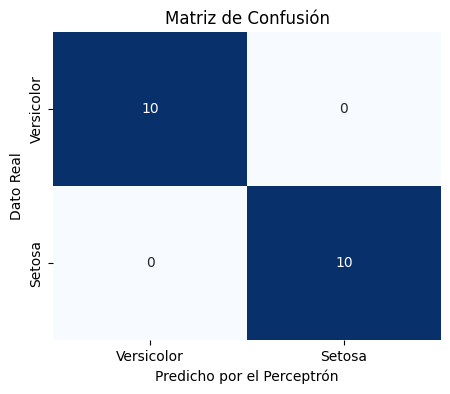

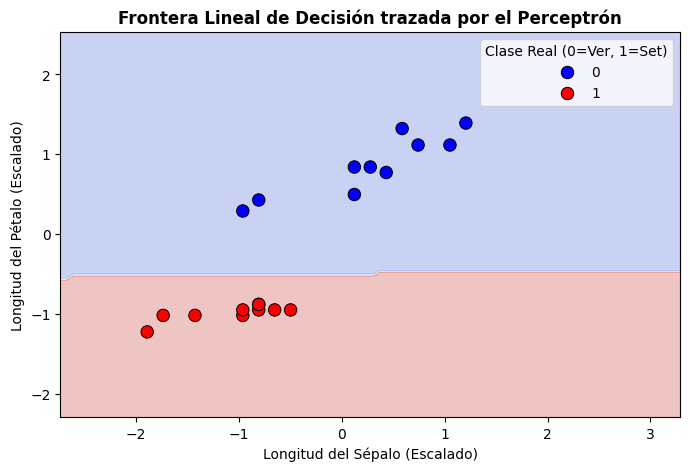

Como el problema era perfectamente lineal, el perceptrón encontró la recta matemática que corta y separa ambos grupos sin equivocarse.


In [12]:
# Importamos las herramientas para evaluar el modelo
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.inspection import DecisionBoundaryDisplay

# El modelo hace sus predicciones sobre los datos de prueba (que no conoce)
y_pred = perceptrón.predict(X_test_scaled)

# Comparamos las predicciones con los datos reales para sacar la exactitud
accuracy = accuracy_score(y_test, y_pred)
print(f"Exactitud (Accuracy) en Prueba: {accuracy * 100:.2f}%")

# Calculamos la Matriz de Confusión
matriz_conf = confusion_matrix(y_test, y_pred)

# Visualizamos la matriz de confusión mediante un mapa de calor (Heatmap)
plt.figure(figsize=(5, 4))
sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Versicolor', 'Setosa'], yticklabels=['Versicolor', 'Setosa'])
plt.title('Matriz de Confusión')
plt.xlabel('Predicho por el Perceptrón')
plt.ylabel('Dato Real')
plt.show()

# VISUALIZACIÓN DE LA FRONTERA DE DECISIÓN

plt.figure(figsize=(8, 5))
# Usamos DecisionBoundaryDisplay de sklearn para pintar el área roja y azul que divide el modelo
DecisionBoundaryDisplay.from_estimator(
    perceptrón,              # Nuestro modelo entrenado
    X_train_scaled,          # Los datos escalados para calcular el rango del plano
    response_method="predict",# El método usado para clasificar cada pixel del fondo
    cmap=plt.cm.coolwarm,    # Colores para la división
    alpha=0.3,               # Transparencia del fondo
    ax=plt.gca()             # Indicamos que se dibuje en el eje gráfico actual
)

# Superponemos los puntos reales de prueba (Test) encima de las áreas pintadas
sns.scatterplot(x=X_test_scaled[:, 0], y=X_test_scaled[:, 1], hue=y_test, palette=['blue', 'red'], edgecolor='k', s=80)
plt.title('Frontera Lineal de Decisión trazada por el Perceptrón', fontweight='bold')
plt.xlabel('Longitud del Sépalo (Escalado)')
plt.ylabel('Longitud del Pétalo (Escalado)')
plt.legend(title='Clase Real (0=Ver, 1=Set)')
plt.show()

print("Como el problema era perfectamente lineal, el perceptrón encontró la recta matemática que corta y separa ambos grupos sin equivocarse.")